# Sensitivity and Counterfactual Analysis

This notebook evaluates how fitted model predictions change when baseline input assumptions or clinical features are modified.

> ⚠️ **Important Note:** These are model-behaviour analyses designed to assess feature stability and input sensitivity. They do **not** represent causal treatment effects.

In [1]:
%load_ext autoreload
%autoreload 2

## 1. Setup and Environment Configuration

We import required data audit tools, configuration parameters, and explainability utilities.
We then isolate the untouched temporal test set.

In [2]:
from pathlib import Path

import yaml
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from icare_risk.data.audit import load_admission_file
from icare_risk.models.training import encode_binary_target
import joblib
from icare_risk.explainability import (
    one_at_a_time_sensitivity,
    evaluate_counterfactuals
)

# Load configuration
CONFIG_PATH = Path('../../src/icare_risk/config/icare/analysis.yaml')
with CONFIG_PATH.open() as f:
    config = yaml.safe_load(f)

# Load processed dataset and encode target
df = load_admission_file(config['outputs']['processed_dataset'])
target = config['columns']['target']
mapping = config.get('target_mapping', config.get('analysis', {}).get('target_mapping', {}))
df['_target_numeric'] = encode_binary_target(
    df[target],
    positive_values=mapping.get('positive_values'),
    negative_values=mapping.get('negative_values'),
)

# Restrict to untouched test set with valid target labels
test = df.loc[df['split'].eq('test') & df['_target_numeric'].notna()].copy()

# Load model pipeline and feature set
model_directory = Path(config['outputs']['model_directory'])
model_names = [m['name'] for m in config.get('models', [])]
model_name = model_names[0]
model_name = "lr_clinical_baseline"
bundle = joblib.load(model_directory / f'{model_name}.joblib')
model = bundle['model'] if isinstance(bundle, dict) and 'model' in bundle else bundle
features = bundle.get('features') if isinstance(bundle, dict) else None

if features is None:
    raise KeyError('Saved model bundle must contain the training feature list.')

X_test = test[features].copy()

print(f'Using model: {model_name}')
print(f'Features: {len(features)}')
print(f'Test rows available: {len(test):,}')

Using model: lr_clinical_baseline
Features: 16
Test rows available: 2,483


## 2. One-at-a-Time (OAT) Sensitivity Analysis

We examine how modifying a single clinical variable (e.g., `AGE_AT_ADMISSION`) across specified realistic values impacts the average model prediction score across the test population.

In [3]:
# Define scenario values for key numerical features available in the test set
scenarios = {
    'AGE_AT_ADMISSION': [50, 65, 80],
}
available = {feature: values for feature, values in scenarios.items() if feature in X_test.columns}
missing = sorted(set(scenarios) - set(available))
if missing:
    print('Skipped missing features:', missing)

sensitivity_table = one_at_a_time_sensitivity(model, X_test, available) if available else pd.DataFrame()
display(sensitivity_table)


,feature,scenario,value,mean_probability,mean_change,median_change
0,AGE_AT_ADMISSION,baseline,NaN,0.506168,0.000000,NaN
1,AGE_AT_ADMISSION,AGE_AT_ADMISSION=50,50.0,0.507141,0.000972,0.000863
2,AGE_AT_ADMISSION,AGE_AT_ADMISSION=65,65.0,0.505004,-0.001164,-0.001251
3,AGE_AT_ADMISSION,AGE_AT_ADMISSION=80,80.0,0.502868,-0.003300,-0.003308


## 3. Named counterfactual scenarios

Each scenario modifies multiple input variables simultaneously. Interpret results as changes in model output under hypothetical inputs, not as treatment effects.

In [4]:
counterfactuals = {
    "older_patient": {
        "AGE_AT_ADMISSION": 80,
    },
    "younger_patient": {
        "AGE_AT_ADMISSION": 50,
    },
}

valid_counterfactuals = {
    name: changes
    for name, changes in counterfactuals.items()
    if all(feature in X_test.columns for feature in changes)
}

print("Model:", model_name)
print("Valid scenarios:", valid_counterfactuals)

counterfactual_table = evaluate_counterfactuals(
    model, X_test, valid_counterfactuals,
)

display(counterfactual_table)


Model: lr_clinical_baseline
Valid scenarios: {'older_patient': {'AGE_AT_ADMISSION': 80}, 'younger_patient': {'AGE_AT_ADMISSION': 50}}


,scenario,n_modified_features,mean_probability,mean_change,median_change
0,baseline,0,0.506168,0.000000,0.000000
1,older_patient,1,0.502868,-0.003300,-0.003308
2,younger_patient,1,0.507141,0.000972,0.000863


## 4. Exporting Sensitivity Artifacts to CSV

To ensure reproducibility and clean pipeline hand-offs, we save both the OAT sensitivity and counterfactual evaluation tables to disk.

In [5]:
output_dir = Path(config['outputs']['sensitivity_directory'])
output_dir.mkdir(parents=True, exist_ok=True)

sensitivity_csv_path = output_dir / f'{model_name}_one_at_a_time.csv'
counterfactual_csv_path = output_dir / f'{model_name}_counterfactuals.csv'

if not sensitivity_table.empty:
    sensitivity_table.to_csv(sensitivity_csv_path, index=False)
if not counterfactual_table.empty:
    counterfactual_table.to_csv(counterfactual_csv_path, index=False)

print(f'Successfully saved results to {output_dir}')

Successfully saved results to results/sensitivity


## 5. Visualizing Sensitivity and Counterfactual Shifts

To maintain rigorous auditing, we load the saved `.csv` artifacts back into memory to render high-resolution publication-quality plots illustrating the change in mean probability across scenarios.

### How to Interpret the Graphs:

#### 1. One-at-a-Time (OAT) Sensitivity Plot (Left)
* **X-Axis:** Represents the feature value being tested (e.g., patient age in years).
* **Y-Axis:** Displays the population-level mean predicted probability of the clinical outcome across the test set.
* **Interpretation:** Slopes indicate directional sensitivity. A rising curve means increasing the feature value increases the model's average risk score, while a flat line suggests the model is robust or insensitive to that specific parameter shift.

#### 2. Counterfactual Scenarios Bar Chart (Right)
* **Y-Axis:** Lists the named hypothetical clinical scenarios (e.g., `older_patient`, `younger_patient`).
* **X-Axis:** Shows the resulting mean predicted probability under that specific multi-feature counterfactual modification compared against the baseline.
* **Interpretation:** Allows clinicians and auditors to verify that the model's behavior aligns with clinical intuition under extreme or archetypal patient profiles without conflating these shifts with causal treatment effects.

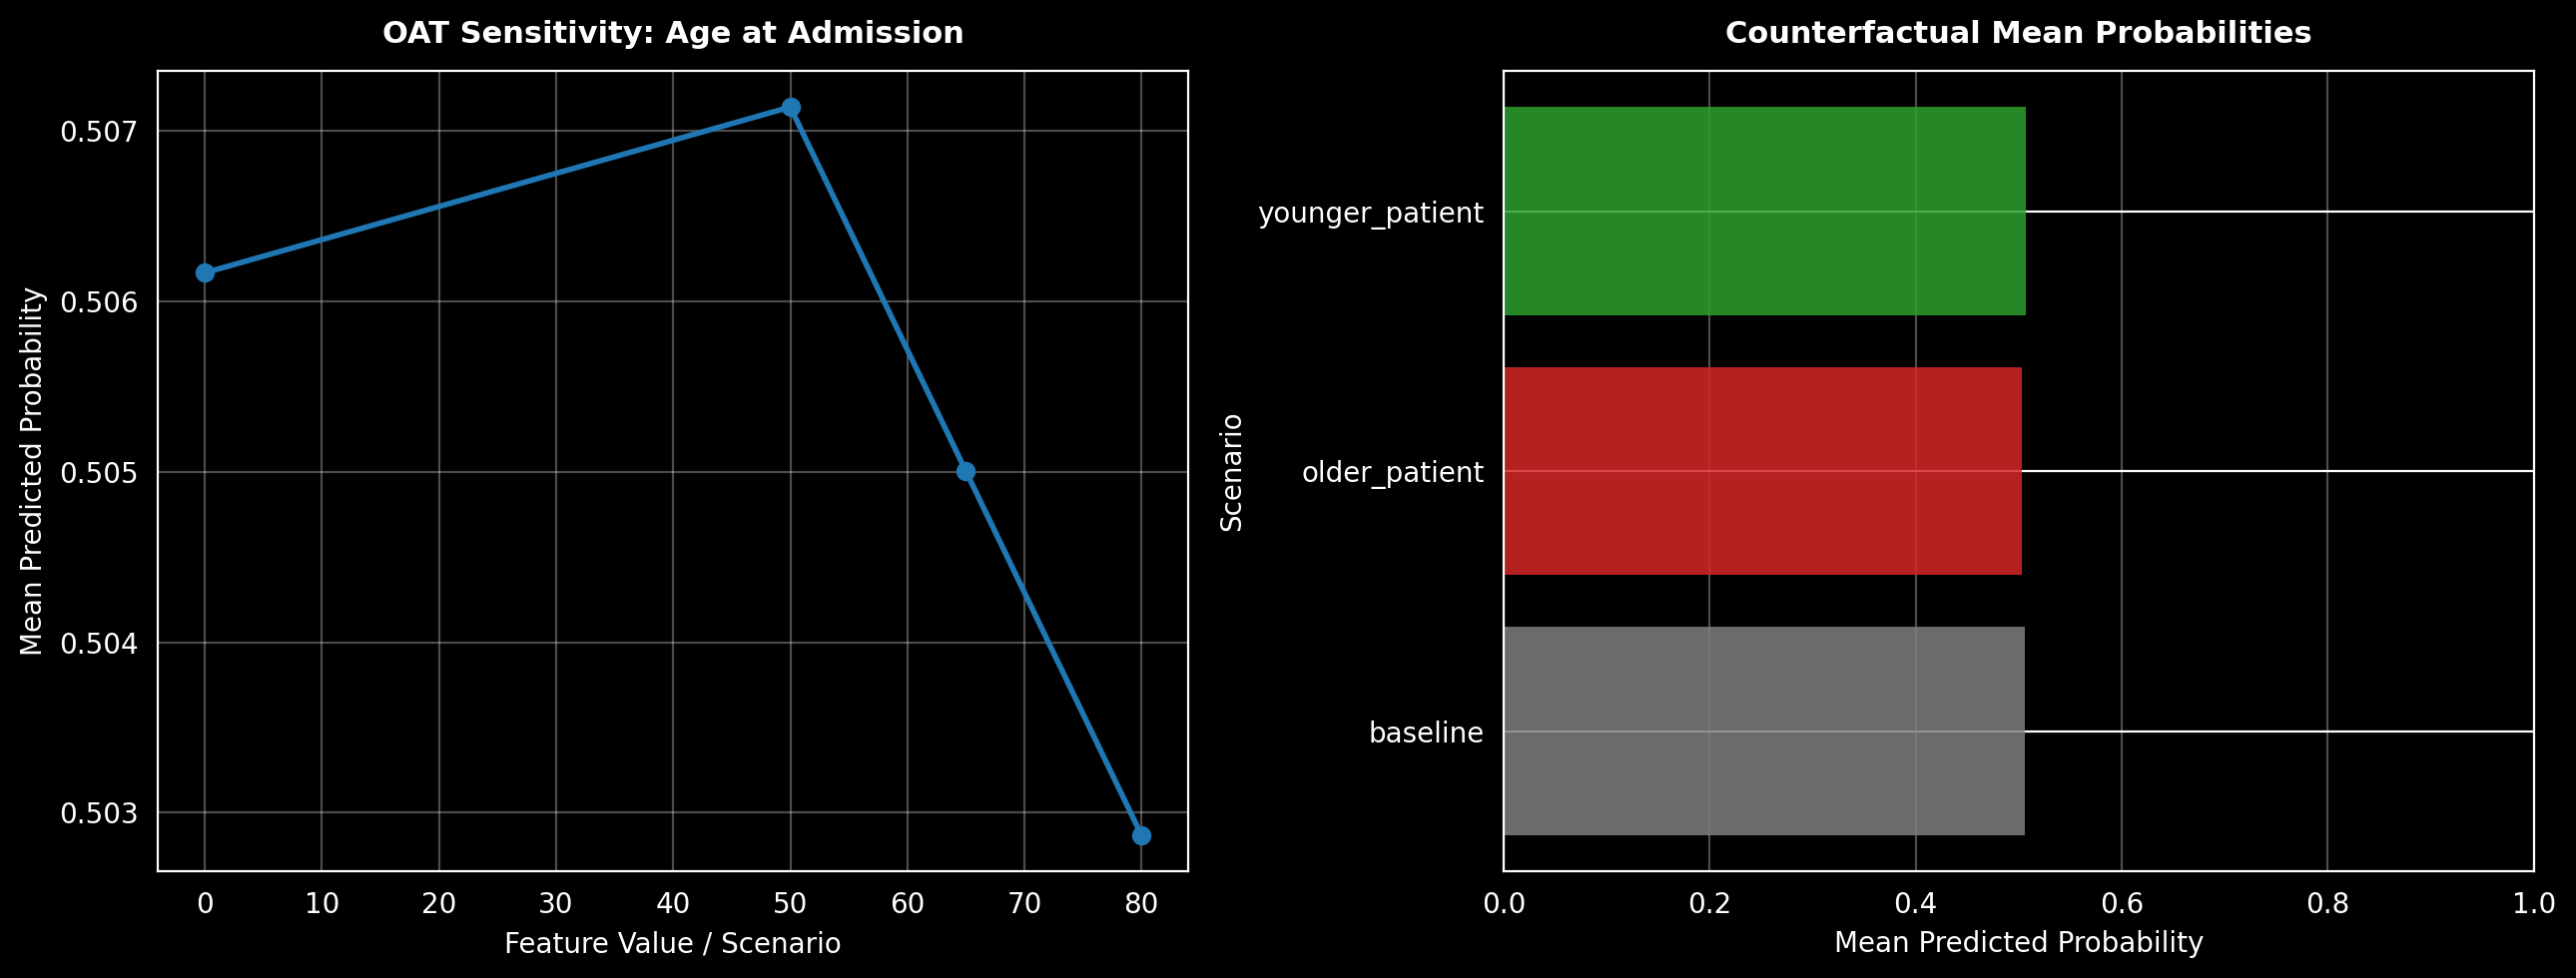

Successfully reloaded CSV data and saved visualization plots to results/sensitivity/lr_clinical_baseline_sensitivity_plots.png


In [6]:
# Load data back from CSV storage
loaded_sensitivity = pd.read_csv(sensitivity_csv_path)
loaded_counterfactuals = pd.read_csv(counterfactual_csv_path)

# Set up figure with dual subplots for OAT sensitivity and counterfactual shifts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=200)

# --- Plot 1: One-at-a-Time Sensitivity ---
if not loaded_sensitivity.empty:
    ax1.plot(
        loaded_sensitivity['value'].fillna(0), # baseline set to 0 or reference point
        loaded_sensitivity['mean_probability'],
        marker='o', linestyle='-', color='#1f77b4', linewidth=2, markersize=6
    )
    ax1.set_title("OAT Sensitivity: Age at Admission", fontsize=11, fontweight="bold", pad=10)
    ax1.set_xlabel("Feature Value / Scenario", fontsize=10)
    ax1.set_ylabel("Mean Predicted Probability", fontsize=10)
    ax1.grid(alpha=0.3)

# --- Plot 2: Counterfactual Shifts ---
if not loaded_counterfactuals.empty:
    scenarios_list = loaded_counterfactuals['scenario']
    mean_probs = loaded_counterfactuals['mean_probability']
    colors = ['#2ca02c' if 'younger' in s else ('#d62728' if 'older' in s else '#7f7f7f') for s in scenarios_list]

    ax2.barh(scenarios_list, mean_probs, color=colors, alpha=0.85, edgecolor='none')
    ax2.set_title("Counterfactual Mean Probabilities", fontsize=11, fontweight="bold", pad=10)
    ax2.set_xlabel("Mean Predicted Probability", fontsize=10)
    ax2.set_ylabel("Scenario", fontsize=10)
    ax2.set_xlim(0, 1.0)
    ax2.grid(axis='x', alpha=0.3)

# Save high-resolution figure artifact
plot_path = output_dir / f'{model_name}_sensitivity_plots.png'
fig.savefig(plot_path, dpi=200, bbox_inches='tight')

plt.tight_layout()
plt.show()

print(f'Successfully reloaded CSV data and saved visualization plots to {plot_path}')